# Generating simulated data files

This notebook takes files generated by Milo's `toliman_sim` and feeds them into the "on-board" processes, firstly writing the raw camera images, and then running the compression service to generate the downlink-ready `netcdf` files.

In [1]:
from workers.sim_converter import rois_to_acquired_frame
from workers.config import SystemConfig
from workers.camera import AcquiredFrame,CameraMode,XimeaCamera
from workers.acquisition import _get_centre_roi, _data_roi_info
from workers.centroid import (
    CENTRE_ROI_LABEL,
    PointingError,
    compute_pointing_error,
)
from workers.writer import FrameWriter
from workers.compression import compress_session, CompressionParams
from supervisor import CspInterface, SessionCommand, command_to_session_config

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from typing import Dict, List, Optional

Import simulated data

In [2]:
core_file = "sim_run_0002_data.npy"
lobe_file = "sim_run_0002_lobes.npy"

core = np.load(core_file)
lobes = np.load(lobe_file)

Fake the on-board system config and commands that would run the imaging session

In [3]:
system = SystemConfig.from_file("config.json")
csp = CspInterface(
    node_address=0,
    command_port=10,
    telemetry_port=11,
    obc_address=1
)
command = SessionCommand(
    session_id="sim_run_0002",
    mode=CameraMode.MULTI_ROI,
    frame_rate_hz = 50.0,
    exposure_us=2_500,
    n_frames=100,
    duration_s=None,
    enable_diagnostics=False
)
session = command_to_session_config(command, system)

centre_offset_x, centre_offset_y = system.centre_roi_offset(session)
data_rois = _data_roi_info(session, system)

Set up the writer processes that save raw camera output to disk.

Then, for each simulated image, insert the core and sidelobe images into an AcquiredFrame object using `sim_converter.rois_to_acquired_frame()`.

__Note that because I neither set up exposure time in the simualation correctly, nor worked out which, if any, parts form the `sim_converter.photons_to_adu()` function still need to be included, I have just inserted a fudge factor `scale` to readjust the simulated image photon counts to a value that won't 'saturate'.__

Next, calculate the pointing error from the centre region-of-interest, and send all ROIs to the writers to get saved to disk.

In [4]:
writers: Dict[str, FrameWriter] = {
        label: FrameWriter(
            data_dir=system.data_dir,
            session_id=session.session_id,
            roi_label=label,
            frame_shape=shape,
            buffer_n_frames=system.writer_ring_buffer_n_frames,
            flush_timeout_s=system.writer_flush_timeout_s,
        )
        for label, shape in data_rois.items()
    }

for w in writers.values():
    w.configure_diagnostics(
        session_id=session.session_id,
        log_dir=system.log_dir,
        enable=True,
    )
    w.start()

scale = 0.15

for i,(c,l) in enumerate(zip(core,lobes)):
    roi_photons = {
        "centre": c*scale,
        "top_right": l[1]*scale,
        "bot_right": l[0]*scale,
        "bot_left": l[3]*scale,
        "top_left": l[2]*scale,
    }
    frame = rois_to_acquired_frame(
        roi_photons=roi_photons,
        session=session,
        frame_id=i,
        camera_model="MC203MG-SY-UB",
    )
    
    centre_roi = _get_centre_roi(frame, session)
    pointing: Optional[PointingError] = None

    if centre_roi is not None:
        pointing = compute_pointing_error(
                        centre_roi=centre_roi,
                        roi_offset_x=centre_offset_x,
                        roi_offset_y=centre_offset_y,
                        sensor_width=system.sensor_width,
                        sensor_height=system.sensor_height,
                        timestamp_ns=frame.timestamp_ns,
                        frame_id=frame.frame_id,
                        min_total_intensity=system.centroid_min_total_intensity,
                    )
        for label, writer in writers.items():
            roi_arr = frame.rois.get(label)
            if roi_arr is not None:
                writer.push(roi_arr, frame)

for w in writers.values():
    w.stop()

Set up the parameters for the compression service.

In [5]:
compress_params = CompressionParams(
    session_id = 'sim_run_0002',
    batch_size_n = 10,
    n_stars = 2,
    kernel_path = 'deconvolution_constant.npy',
    sidelobe_offset = 1625,
    strip_width=6,
    corner_roi_labels = ['top_right','bot_right','bot_left','top_left'],
    centre_roi_label = 'centre'
)

Run the compression pipeline

In [6]:
compress_session(system,session,compress_params)

Check the output

In [7]:
import xarray as xr
from pathlib import Path

In [8]:
data_dir = Path(system.data_dir)
filename = compress_params.session_id+'_batch0000.nc'

In [9]:
data = xr.open_dataset(data_dir / filename)

In [10]:
data

<xarray.Dataset>
Dimensions:               (centre_row: 128, centre_col: 128, diff_frame: 9,
                           sl_row: 200, sl_col: 48, frame: 10)
Dimensions without coordinates: centre_row, centre_col, diff_frame, sl_row,
                                sl_col, frame
Data variables:
    centre_reference      (centre_row, centre_col) uint16 ...
    centre_differences    (diff_frame, centre_row, centre_col) float32 ...
    sidelobe_reference    (sl_row, sl_col) uint16 ...
    sidelobe_differences  (diff_frame, sl_row, sl_col) float32 ...
    timestamp_ns          (frame) int64 ...
    frame_id              (frame) int64 ...
    host_time             (frame) timedelta64[ns] ...
    nframes_dropped       (frame) int32 ...
Attributes:
    session_id:     sim_run_0002
    batch_size:     10
    n_stars:        2
    corner_angles:  {'top_left': 45.0, 'top_right': 135.0, 'bot_left': 135.0,...
    strip_width:    6
    conventions:    CF-1.8

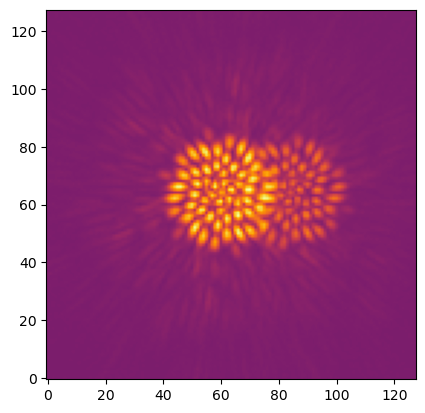

In [11]:
plt.figure()
plt.imshow(data.centre_reference,origin='lower',cmap='inferno', norm=PowerNorm(0.3, vmin=0));

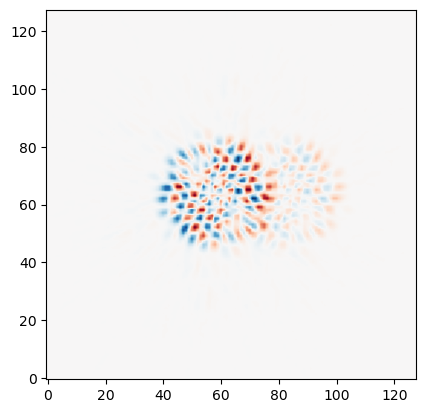

In [12]:
plt.figure()
plt.imshow(data.centre_differences[0],origin='lower',cmap='RdBu');

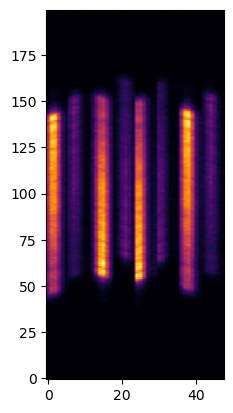

In [13]:
plt.figure()
plt.imshow(data.sidelobe_reference,origin='lower',cmap='inferno', aspect=0.5);

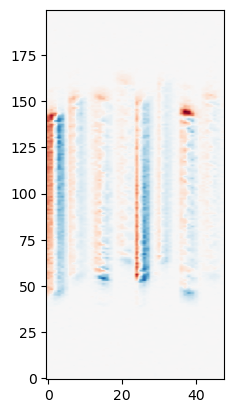

In [14]:
plt.figure()
img = data.sidelobe_differences[0]
max_value = np.max([np.max(img),np.abs(np.min(img))])
plt.imshow(img,origin='lower',cmap='RdBu', aspect=0.5, vmin=-max_value, vmax=max_value);